# Sentinel-1 and WorldCover training data (2021)

The training inputs and urban additions are annual 2021 Sentinel-1 VV/VH composites. The labels are ESA WorldCover 2021 (v200). Saved dataset files are supplied. These historical collection cells can write to Google Drive. The unrelated exploratory query is preserved in the original backup.

In [ ]:
!pip install -q earthengine-api geemap rasterio

In [ ]:
import ee
import geemap

# Authenticate your Google account
ee.Authenticate()

In [9]:
import ee
import geemap

PROJECT_ID = "mydataportfolio-484121"

ee.Initialize(project=PROJECT_ID)

print("Earth Engine connected successfully!")

Earth Engine connected successfully!


In [10]:
import ee
import geemap
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ID = "mydataportfolio-484121"

ee.Initialize(project=PROJECT_ID)

print("Earth Engine is ready!")

Earth Engine is ready!


In [11]:
# Approximate Baden-Württemberg study area
study_area = ee.Geometry.Rectangle([
    7.5, 47.5,   # Southwest: longitude, latitude
    10.5, 49.8    # Northeast: longitude, latitude
])

print("Study area created successfully!")

Study area created successfully!


In [14]:
import ee

# Define study area (approximate Baden-Württemberg)
study_area = ee.Geometry.Rectangle([
    7.5, 47.5,
    10.5, 49.8
])

# Load Sentinel-1 images from 2021
sentinel1 = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(study_area)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
    .select(["VV", "VH"])
)

print("Sentinel-1 images:", sentinel1.size().getInfo())

Sentinel-1 images: 943


In [15]:
first_image = ee.Image(sentinel1.first())

print("Available bands:", first_image.bandNames().getInfo())

print(
    "Image date:",
    ee.Date(first_image.get("system:time_start"))
    .format("YYYY-MM-dd").getInfo()
)

print("Satellite:", first_image.get("platform_number").getInfo())

Available bands: ['VV', 'VH']
Image date: 2021-01-01
Satellite: A


In [17]:
import geemap

# Create a map without OpenStreetMap background
Map = geemap.Map(
    center=[48.5, 9.0],
    zoom=7,
    basemap="Esri.WorldImagery"
)

# Create Sentinel-1 median composite
sentinel1_composite = sentinel1.median()

# Add Sentinel-1 VV layer
Map.addLayer(
    sentinel1_composite.select("VV"),
    {"min": -25, "max": 0},
    "Sentinel-1 VV 2021"
)

# Add Sentinel-1 VH layer
Map.addLayer(
    sentinel1_composite.select("VH"),
    {"min": -30, "max": -5},
    "Sentinel-1 VH 2021",
    False
)

# Add study area
Map.addLayer(
    study_area,
    {"color": "red"},
    "Study Area"
)

Map

Map(center=[48.5, 9.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', t…

In [18]:
# Check number of Sentinel-1 images
total_images = sentinel1.size().getInfo()

print("Total Sentinel-1 images:", total_images)

# Check coverage of the study area
study_images = sentinel1.filterBounds(study_area)

print(
    "Images intersecting study area:",
    study_images.size().getInfo()
)

# Check the bands
print(
    "Available bands:",
    sentinel1.first().bandNames().getInfo()
)

Total Sentinel-1 images: 943
Images intersecting study area: 943
Available bands: ['VV', 'VH']


In [19]:
# Count valid Sentinel-1 observations at each pixel
coverage = sentinel1.select("VV").count()

# Create a new map
coverage_map = geemap.Map(
    center=[48.5, 9.0],
    zoom=7,
    basemap="Esri.WorldImagery"
)

# Display observation counts
coverage_map.addLayer(
    coverage,
    {
        "min": 0,
        "max": 100,
        "palette": ["red", "yellow", "green"]
    },
    "Sentinel-1 Observation Count"
)

# Display study area
coverage_map.addLayer(
    study_area,
    {"color": "blue"},
    "Study Area"
)

coverage_map

Map(center=[48.5, 9.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', t…

In [20]:
# Load ESA WorldCover 2021
worldcover = ee.ImageCollection(
    "ESA/WorldCover/v200"
).first().select("Map")

# Check available land-cover classes
print("WorldCover band:", worldcover.bandNames().getInfo())

# Create map
landcover_map = geemap.Map(
    center=[48.5, 9.0],
    zoom=7,
    basemap="Esri.WorldImagery"
)

# Display land-cover labels
landcover_map.addLayer(
    worldcover.clip(study_area),
    {
        "min": 10,
        "max": 100,
        "palette": [
            "006400",  # Trees
            "ffbb22",  # Shrubland
            "ffff4c",  # Grassland
            "f096ff",  # Cropland
            "fa0000",  # Built-up
            "b4b4b4",  # Bare land
            "f0f0f0",  # Snow and ice
            "0064c8",  # Water
            "0096a0",  # Wetland
            "00cf75",  # Mangroves
            "fae6a0"   # Moss and lichen
        ]
    },
    "ESA WorldCover 2021"
)

landcover_map

WorldCover band: ['Map']


Map(center=[48.5, 9.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', t…

In [21]:
# ESA WorldCover class codes
class_values = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]

# Correct class colors
class_colors = [
    "006400",  # Tree cover
    "ffbb22",  # Shrubland
    "ffff4c",  # Grassland
    "f096ff",  # Cropland
    "fa0000",  # Built-up
    "b4b4b4",  # Bare / sparse vegetation
    "f0f0f0",  # Snow and ice
    "0064c8",  # Water
    "0096a0",  # Herbaceous wetland
    "00cf75",  # Mangroves
    "fae6a0"   # Moss and lichen
]

# Remap WorldCover codes to 0-10
worldcover_display = worldcover.remap(
    class_values,
    list(range(11))
)

# Create map
Map = geemap.Map(
    center=[48.5, 9.0],
    zoom=7,
    basemap="Esri.WorldImagery"
)

Map.addLayer(
    worldcover_display.clip(study_area),
    {"min": 0, "max": 10, "palette": class_colors},
    "ESA WorldCover 2021"
)

Map

Map(center=[48.5, 9.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', t…

In [22]:
# Load German state boundaries
states = ee.FeatureCollection("FAO/GAUL/2015/level1")

# Filter Germany
germany_states = states.filter(
    ee.Filter.eq("ADM0_NAME", "Germany")
)

# Inspect available state names
state_names = germany_states.aggregate_array(
    "ADM1_NAME"
).getInfo()

print("German states:", state_names)

German states: ['Baden-Wuerttemberg', 'Bayern', 'Berlin', 'Brandenburg', 'Bremen', 'Hamburg', 'Hessen', 'Mecklenburg-Vorpommern', 'Niedersachsen', 'Nordrhein-Westfalen', 'Rheinland-Pfalz', 'Saarland', 'Sachsen', 'Sachsen-Anhalt', 'Schleswig-Holstein', 'Thueringen']


In [23]:
# Select Baden-Württemberg
baden_wurttemberg = germany_states.filter(
    ee.Filter.eq("ADM1_NAME", "Baden-Wuerttemberg")
)

# Get the actual state geometry
study_area = baden_wurttemberg.geometry()

# Check the result
print(
    "Number of matching states:",
    baden_wurttemberg.size().getInfo()
)

# Create a map
Map = geemap.Map(
    center=[48.6, 9.0],
    zoom=7,
    basemap="Esri.WorldImagery"
)

# Display Baden-Württemberg boundary
Map.addLayer(
    baden_wurttemberg.style(
        color="red",
        fillColor="00000000",
        width=3
    ),
    {},
    "Baden-Württemberg Boundary"
)

Map.centerObject(baden_wurttemberg, 7)

Map

Number of matching states: 1


Map(center=[48.5366095360058, 9.039468295327715], controls=(WidgetControl(options=['position', 'transparent_bg…

In [24]:
# Load Sentinel-1 data using the actual state boundary
sentinel1_train = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(study_area)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
    .select(["VV", "VH"])
)

# Count available images
print(
    "Training images:",
    sentinel1_train.size().getInfo()
)

# Create median composite
train_image = sentinel1_train.median().clip(study_area)

# Check input bands
print(
    "Training bands:",
    train_image.bandNames().getInfo()
)

Training images: 464
Training bands: ['VV', 'VH']


In [25]:
# Prepare Sentinel-1 input bands
sar_image = train_image.select(["VV", "VH"])

# Prepare ESA WorldCover labels
label_image = worldcover.select("Map").clip(study_area)

# Get the projection of Sentinel-1
sar_projection = sar_image.select("VV").projection()

print("SAR projection:", sar_projection.getInfo())

# Use the SAR projection as our common grid
aligned_labels = label_image.reproject(
    crs=sar_projection,
    scale=10
)

# Combine radar inputs and land-cover labels
training_stack = sar_image.addBands(
    aligned_labels.rename("label")
)

print(
    "Combined bands:",
    training_stack.bandNames().getInfo()
)

SAR projection: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}
Combined bands: ['VV', 'VH', 'label']


In [26]:
# Define a common coordinate system
EXPORT_CRS = "EPSG:3035"

# Define pixel resolution in meters
PIXEL_SIZE = 10

# Select radar input bands
sar_image = train_image.select(["VV", "VH"])

# Select WorldCover training labels
label_image = worldcover.select("Map").clip(study_area)

# Keep labels categorical using nearest-neighbor sampling
label_image = label_image.resample("nearest") if False else label_image

# Combine inputs and labels
training_stack = sar_image.addBands(
    label_image.rename("label")
)

print("Export CRS:", EXPORT_CRS)
print("Pixel size:", PIXEL_SIZE, "meters")
print("Training bands:", training_stack.bandNames().getInfo())

Export CRS: EPSG:3035
Pixel size: 10 meters
Training bands: ['VV', 'VH', 'label']


In [30]:
import ee
import geemap

# Sample location near Stuttgart
sample_point = ee.Geometry.Point([9.18, 48.78])

# Create a square region approximately 2.56 km wide
sample_region = sample_point.buffer(1280).bounds(maxError=1)

print("Sample region created successfully!")

# Create interactive map
patch_map = geemap.Map(
    center=[48.78, 9.18],
    zoom=12,
    basemap="Esri.WorldImagery"
)

# Display WorldCover labels
patch_map.addLayer(
    worldcover_display.clip(sample_region),
    {
        "min": 0,
        "max": 10,
        "palette": class_colors
    },
    "WorldCover Labels"
)

# Draw red boundary
patch_map.addLayer(
    ee.FeatureCollection([
        ee.Feature(sample_region)
    ]).style(
        color="red",
        fillColor="00000000",
        width=3
    ),
    {},
    "Sample Patch"
)

# Center the map
patch_map.centerObject(sample_region, 12)

patch_map

Sample region created successfully!


Map(center=[48.78000176760495, 9.180027970770137], controls=(WidgetControl(options=['position', 'transparent_b…

In [31]:
# Get the center point in EPSG:3035 coordinates
center = sample_point.transform(
    ee.Projection(EXPORT_CRS), 1
).coordinates().getInfo()

# Snap the patch to a 10-meter grid
import math

cx = round(center[0] / 10) * 10
cy = round(center[1] / 10) * 10

# Exact 256 x 256 pixels at 10 meters
xmin = cx - 1280
ymax = cy + 1280

# Define exact pixel grid
patch_transform = [
    10, 0, xmin,
    0, -10, ymax
]

# Define export region
export_region = ee.Geometry.Rectangle(
    [xmin, ymax - 2560, xmin + 2560, ymax],
    proj=EXPORT_CRS,
    geodesic=False
)

# Prepare the three bands
export_image = (
    sar_image.select(["VV", "VH"])
    .addBands(label_image.rename("label"))
    .toFloat()
)

print("Patch dimensions: 256 x 256")
print("Resolution: 10 meters")
print("Bands:", export_image.bandNames().getInfo())

Patch dimensions: 256 x 256
Resolution: 10 meters
Bands: ['VV', 'VH', 'label']


In [32]:
task = ee.batch.Export.image.toDrive(
    image=export_image,
    description="Stuttgart_LULC_Training_Patch_01",
    folder="LULC_Project",
    fileNamePrefix="stuttgart_patch_01",
    region=export_region,
    crs=EXPORT_CRS,
    crsTransform=patch_transform,
    fileFormat="GeoTIFF",
    maxPixels=1000000
)

task.start()

print("Export task started!")
print("Task ID:", task.id)

Export task started!
Task ID: PLHC7HNMV62GAGJKHIBJDSIU


In [33]:
print(task.status())

{'state': 'RUNNING', 'description': 'Stuttgart_LULC_Training_Patch_01', 'priority': 100, 'creation_timestamp_ms': 1793913447036, 'update_timestamp_ms': 1793913451723, 'start_timestamp_ms': 1793913451663, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'id': 'PLHC7HNMV62GAGJKHIBJDSIU', 'name': 'projects/mydataportfolio-484121/operations/PLHC7HNMV62GAGJKHIBJDSIU'}


In [34]:
import time

while True:
    status = task.status()
    state = status["state"]

    print("Export status:", state)

    if state == "COMPLETED":
        print("Export completed successfully!")
        break

    elif state in ["FAILED", "CANCELLED"]:
        print("Export stopped:", status.get("error_message", "No details"))
        break

    time.sleep(10)

Export status: RUNNING
Export status: RUNNING
Export status: RUNNING
Export status: RUNNING
Export status: RUNNING
Export status: RUNNING
Export status: COMPLETED
Export completed successfully!


In [35]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [36]:
import rasterio
import numpy as np

# Location of exported training patch
file_path = "/content/drive/MyDrive/LULC_Project/stuttgart_patch_01.tif"

# Open the GeoTIFF
with rasterio.open(file_path) as src:

    print("Width:", src.width)
    print("Height:", src.height)
    print("Number of bands:", src.count)
    print("Coordinate system:", src.crs)
    print("Pixel resolution:", src.res)

    # Read individual bands
    vv = src.read(1)
    vh = src.read(2)
    labels = src.read(3)

# Inspect data
print("\nVV shape:", vv.shape)
print("VH shape:", vh.shape)
print("Labels shape:", labels.shape)

print("\nUnique land-cover labels:")
print(np.unique(labels))

print("\nValid VV pixels:", np.isfinite(vv).sum())
print("Valid VH pixels:", np.isfinite(vh).sum())

Width: 257
Height: 257
Number of bands: 3
Coordinate system: EPSG:3035
Pixel resolution: (10.0, 10.0)

VV shape: (257, 257)
VH shape: (257, 257)
Labels shape: (257, 257)

Unique land-cover labels:
[10. 30. 40. 50. 60. 80. nan]

Valid VV pixels: 65536
Valid VH pixels: 65536


In [37]:
import numpy as np

# Check valid and missing pixels
print("VV valid pixels:", np.isfinite(vv).sum())
print("VH valid pixels:", np.isfinite(vh).sum())
print("Label valid pixels:", np.isfinite(labels).sum())

print("\nVV missing pixels:", np.isnan(vv).sum())
print("VH missing pixels:", np.isnan(vh).sum())
print("Label missing pixels:", np.isnan(labels).sum())

# Find valid pixels across all three bands
valid_mask = (
    np.isfinite(vv) &
    np.isfinite(vh) &
    np.isfinite(labels)
)

print("\nFully valid pixels:", valid_mask.sum())

# Check label distribution, excluding NaN
unique, counts = np.unique(
    labels[np.isfinite(labels)],
    return_counts=True
)

print("\nLand-cover class distribution:")

for class_id, count in zip(unique, counts):
    print(f"Class {int(class_id)}: {count} pixels")

VV valid pixels: 65536
VH valid pixels: 65536
Label valid pixels: 65536

VV missing pixels: 513
VH missing pixels: 513
Label missing pixels: 513

Fully valid pixels: 65536

Land-cover class distribution:
Class 10: 19318 pixels
Class 30: 843 pixels
Class 40: 7 pixels
Class 50: 45128 pixels
Class 60: 5 pixels
Class 80: 235 pixels


In [38]:
print("First row valid:", valid_mask[0, :].sum())
print("Last row valid:", valid_mask[-1, :].sum())

print("First column valid:", valid_mask[:, 0].sum())
print("Last column valid:", valid_mask[:, -1].sum())

First row valid: 0
Last row valid: 256
First column valid: 256
Last column valid: 0


In [39]:
# Find the rows and columns containing valid pixels
rows, cols = np.where(valid_mask)

r0, r1 = rows.min(), rows.max() + 1
c0, c1 = cols.min(), cols.max() + 1

# Extract the valid area
vv_clean = vv[r0:r1, c0:c1]
vh_clean = vh[r0:r1, c0:c1]
labels_clean = labels[r0:r1, c0:c1]

print("VV:", vv_clean.shape)
print("VH:", vh_clean.shape)
print("Labels:", labels_clean.shape)

print(
    "All pixels valid:",
    np.isfinite(vv_clean).all()
    and np.isfinite(vh_clean).all()
    and np.isfinite(labels_clean).all()
)

VV: (256, 256)
VH: (256, 256)
Labels: (256, 256)
All pixels valid: True


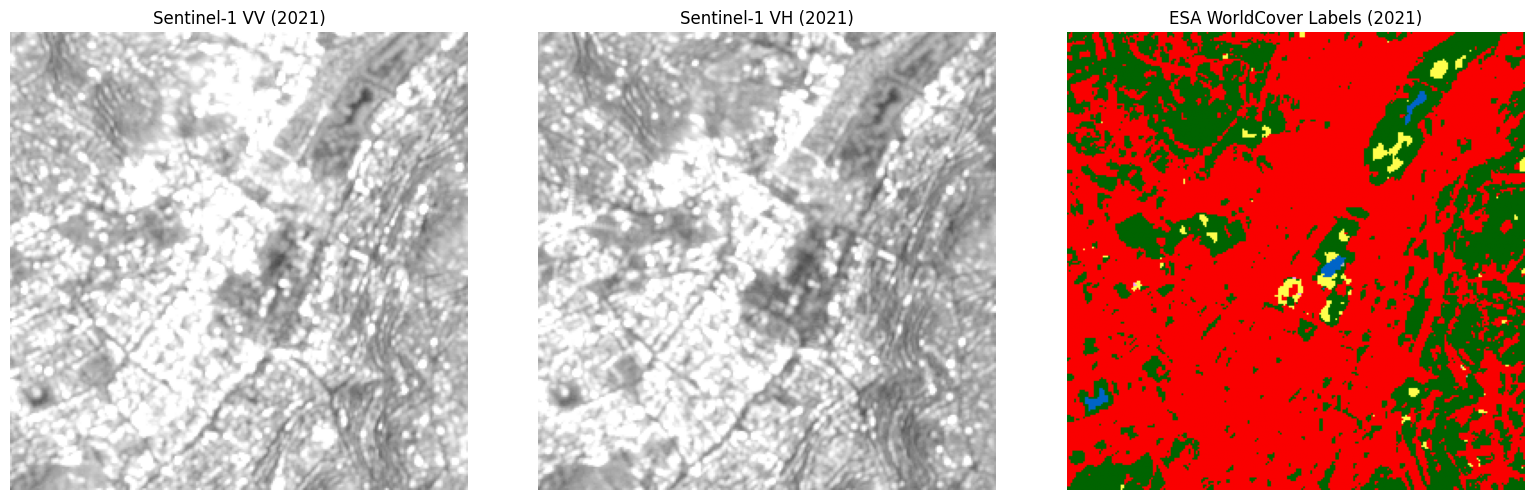

In [40]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Sentinel-1 VV
axes[0].imshow(vv_clean, cmap="gray", vmin=-25, vmax=0)
axes[0].set_title("Sentinel-1 VV (2021)")
axes[0].axis("off")

# Sentinel-1 VH
axes[1].imshow(vh_clean, cmap="gray", vmin=-30, vmax=-5)
axes[1].set_title("Sentinel-1 VH (2021)")
axes[1].axis("off")

# WorldCover labels
from matplotlib.colors import ListedColormap, BoundaryNorm

worldcover_codes = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]

label_indices = np.searchsorted(worldcover_codes, labels_clean)

cmap = ListedColormap(["#" + color for color in class_colors])
norm = BoundaryNorm(np.arange(-0.5, 11.5, 1), cmap.N)

axes[2].imshow(label_indices, cmap=cmap, norm=norm)
axes[2].set_title("ESA WorldCover Labels (2021)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [41]:
import numpy as np
import os

# Create dataset folder in Google Drive
save_folder = "/content/drive/MyDrive/LULC_Project/dataset"
os.makedirs(save_folder, exist_ok=True)

# Combine VV and VH into two input channels
X = np.stack([vv_clean, vh_clean], axis=0).astype(np.float32)

# Keep the original WorldCover class codes
y = labels_clean.astype(np.uint8)

# Save the training patch
save_path = os.path.join(
    save_folder,
    "stuttgart_patch_01.npz"
)

np.savez_compressed(
    save_path,
    X=X,
    y=y
)

print("Training patch saved successfully!")
print("Input shape:", X.shape)
print("Label shape:", y.shape)
print("Saved at:", save_path)

Training patch saved successfully!
Input shape: (2, 256, 256)
Label shape: (256, 256)
Saved at: /content/drive/MyDrive/LULC_Project/dataset/stuttgart_patch_01.npz


In [42]:
# Candidate training locations in Baden-Württemberg
training_locations = {
    "Stuttgart": [9.18, 48.78],
    "Karlsruhe": [8.40, 49.01],
    "Freiburg": [7.85, 48.00],
    "Heidelberg": [8.69, 49.40],
    "Mannheim": [8.47, 49.49],
    "Ulm": [9.99, 48.40],
    "Tuebingen": [9.06, 48.52],
    "Heilbronn": [9.22, 49.14],
    "Offenburg": [7.94, 48.47],
    "Ravensburg": [9.61, 47.78]
}

print("Number of candidate locations:", len(training_locations))

for city, coordinates in training_locations.items():
    print(city, coordinates)


Number of candidate locations: 10
Stuttgart [9.18, 48.78]
Karlsruhe [8.4, 49.01]
Freiburg [7.85, 48.0]
Heidelberg [8.69, 49.4]
Mannheim [8.47, 49.49]
Ulm [9.99, 48.4]
Tuebingen [9.06, 48.52]
Heilbronn [9.22, 49.14]
Offenburg [7.94, 48.47]
Ravensburg [9.61, 47.78]


In [43]:
import ee

def export_training_patch(city, coordinates):

    # Longitude and latitude
    lon, lat = coordinates

    # Convert location to projected coordinates
    point = ee.Geometry.Point([lon, lat])

    center = point.transform(
        ee.Projection(EXPORT_CRS), 1
    ).coordinates().getInfo()

    # Snap coordinates to the 10-meter grid
    cx = round(center[0] / 10) * 10
    cy = round(center[1] / 10) * 10

    # Exact patch boundaries
    xmin = cx - 1280
    ymax = cy + 1280

    # Pixel grid for 256 x 256 pixels
    transform = [
        10, 0, xmin,
        0, -10, ymax
    ]

    # Export region
    region = ee.Geometry.Rectangle(
        [
            xmin,
            ymax - 2560,
            xmin + 2560,
            ymax
        ],
        proj=EXPORT_CRS,
        geodesic=False
    )

    # Export the Sentinel-1 and WorldCover bands
    image = (
        sar_image.select(["VV", "VH"])
        .addBands(label_image.rename("label"))
        .toFloat()
    )

    # Start export to Google Drive
    task = ee.batch.Export.image.toDrive(
        image=image,
        description=f"LULC_{city}_2021",
        folder="LULC_Project",
        fileNamePrefix=f"{city.lower()}_patch_01",
        region=region,
        crs=EXPORT_CRS,
        crsTransform=transform,
        fileFormat="GeoTIFF",
        maxPixels=1000000
    )

    task.start()

    print(f"Export started: {city}")

    return task

print("Automatic export function created successfully!")

Automatic export function created successfully!


In [44]:
# Export a training patch for Karlsruhe
karlsruhe_task = export_training_patch(
    "Karlsruhe",
    training_locations["Karlsruhe"]
)

print(karlsruhe_task.status())

Export started: Karlsruhe
{'state': 'READY', 'description': 'LULC_Karlsruhe_2021', 'priority': 100, 'creation_timestamp_ms': 1793913931638, 'update_timestamp_ms': 1793913931638, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'BHBZ4T2SIPEXQU26XELG4JO2', 'name': 'projects/mydataportfolio-484121/operations/BHBZ4T2SIPEXQU26XELG4JO2'}


In [45]:
import time

while True:
    status = karlsruhe_task.status()
    state = status["state"]

    print("Karlsruhe export:", state)

    if state == "COMPLETED":
        print("Karlsruhe patch exported successfully!")
        break

    if state in ["FAILED", "CANCELLED"]:
        print("Export error:", status.get("error_message"))
        break

    time.sleep(10)

Karlsruhe export: RUNNING
Karlsruhe export: COMPLETED
Karlsruhe patch exported successfully!


In [46]:
print("Study area:", study_area is not None)
print("SAR bands:", sar_image.bandNames().getInfo())
print("Label bands:", label_image.bandNames().getInfo())
print("Export CRS:", EXPORT_CRS)

Study area: True
SAR bands: ['VV', 'VH']
Label bands: ['Map']
Export CRS: EPSG:3035


In [47]:
import ee

# Generate 120 random locations across Baden-Württemberg
candidate_points = ee.FeatureCollection.randomPoints(
    region=study_area,
    points=120,
    seed=42,
    maxError=100
)

# Extract coordinates from individual points
coordinates = [
    feature["geometry"]["coordinates"]
    for feature in candidate_points.getInfo()["features"]
]

print("Candidate locations:", len(coordinates))
print("First 5 locations:", coordinates[:5])

Candidate locations: 120
First 5 locations: [[8.964508607565648, 47.96931977168725], [9.044894995492406, 48.80032675949876], [8.238534377425355, 47.98650443766088], [8.325818551570272, 48.211689997576556], [7.942889554804357, 48.316249350963275]]


In [48]:
import ee

def export_patch(name, lon, lat):
    # Convert location to EPSG:3035
    point = ee.Geometry.Point([lon, lat])
    center = point.transform(
        ee.Projection(EXPORT_CRS), 1
    ).coordinates().getInfo()

    # Snap coordinates to 10-meter grid
    cx = round(center[0] / 10) * 10
    cy = round(center[1] / 10) * 10

    xmin = cx - 1280
    ymax = cy + 1280

    # Exact pixel grid
    transform = [
        10, 0, xmin,
        0, -10, ymax
    ]

    # Slightly inset region to avoid extra border pixels
    region = ee.Geometry.Rectangle(
        [
            xmin + 0.1,
            ymax - 2560 + 0.1,
            xmin + 2560 - 0.1,
            ymax - 0.1
        ],
        proj=EXPORT_CRS,
        geodesic=False
    )

    # Combine radar inputs and training labels
    image = (
        sar_image.select(["VV", "VH"])
        .addBands(label_image.rename("label"))
        .toFloat()
    )

    # Export to Google Drive
    task = ee.batch.Export.image.toDrive(
        image=image,
        description=f"LULC_{name}",
        folder="LULC_Project_Batch",
        fileNamePrefix=f"patch_{name}",
        region=region,
        crs=EXPORT_CRS,
        crsTransform=transform,
        fileFormat="GeoTIFF",
        maxPixels=1000000
    )

    task.start()
    return task

print("Export function ready!")

Export function ready!


In [49]:
import time

tasks = []

for i, (lon, lat) in enumerate(coordinates[:12]):
    task = export_patch(
        name=f"{i:03d}",
        lon=lon,
        lat=lat
    )

    tasks.append(task)
    print(f"Submitted patch {i + 1}/12")

    time.sleep(1)

print("All 12 export tasks submitted!")

Submitted patch 1/12
Submitted patch 2/12
Submitted patch 3/12
Submitted patch 4/12
Submitted patch 5/12
Submitted patch 6/12
Submitted patch 7/12
Submitted patch 8/12
Submitted patch 9/12
Submitted patch 10/12
Submitted patch 11/12
Submitted patch 12/12
All 12 export tasks submitted!


In [50]:
import time

while True:
    states = [task.status()["state"] for task in tasks]

    completed = states.count("COMPLETED")
    running = states.count("RUNNING")
    ready = states.count("READY")
    failed = states.count("FAILED")
    cancelled = states.count("CANCELLED")

    print(
        f"Completed: {completed}/12 | "
        f"Running: {running} | "
        f"Ready: {ready} | "
        f"Failed: {failed}"
    )

    if completed + failed + cancelled == len(tasks):
        break

    time.sleep(30)

print("\nAll export tasks have finished.")

for i, task in enumerate(tasks):
    status = task.status()

    if status["state"] != "COMPLETED":
        print(
            f"Patch {i:03d}:",
            status["state"],
            status.get("error_message", "")
        )

Completed: 2/12 | Running: 1 | Ready: 9 | Failed: 0
Completed: 4/12 | Running: 0 | Ready: 8 | Failed: 0
Completed: 4/12 | Running: 2 | Ready: 6 | Failed: 0
Completed: 6/12 | Running: 2 | Ready: 4 | Failed: 0
Completed: 10/12 | Running: 2 | Ready: 0 | Failed: 0
Completed: 12/12 | Running: 0 | Ready: 0 | Failed: 0

All export tasks have finished.


In [51]:
from google.colab import drive
import glob
import os

drive.mount("/content/drive")

folder = "/content/drive/MyDrive/LULC_Project_Batch"

files = sorted(glob.glob(
    os.path.join(folder, "patch_*.tif")
))

print("Files found:", len(files))
print("First 3 files:", [os.path.basename(f) for f in files[:3]])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files found: 12
First 3 files: ['patch_000.tif', 'patch_001.tif', 'patch_002.tif']


In [52]:
import rasterio
import numpy as np

valid_patches = []
valid_names = []

worldcover_codes = {
    10, 20, 30, 40, 50, 60,
    70, 80, 90, 95, 100
}

for file in files:

    with rasterio.open(file) as src:
        data = src.read()
        crs = str(src.crs)
        resolution = src.res

    if data.shape[0] != 3:
        print("SKIPPED (bands):", os.path.basename(file))
        continue

    valid = np.isfinite(data).all(axis=0)

    rows, cols = np.where(valid)

    if len(rows) == 0:
        print("SKIPPED (empty):", os.path.basename(file))
        continue

    # Crop to bounding box of valid pixels
    r0, r1 = rows.min(), rows.max() + 1
    c0, c1 = cols.min(), cols.max() + 1

    cleaned = data[:, r0:r1, c0:c1]

    # Check dimensions, missing values and projection
    if cleaned.shape != (3, 256, 256):
        print("SKIPPED (shape):", os.path.basename(file), cleaned.shape)
        continue

    if not np.isfinite(cleaned).all():
        print("SKIPPED (missing pixels):", os.path.basename(file))
        continue

    if crs != "EPSG:3035" or not np.allclose(resolution, (10, 10)):
        print("SKIPPED (projection):", os.path.basename(file))
        continue

    labels = cleaned[2]

    if not np.all(np.isin(labels, list(worldcover_codes))):
        print("SKIPPED (invalid labels):", os.path.basename(file))
        continue

    valid_patches.append(cleaned)
    valid_names.append(os.path.basename(file))

    print("VALID:", os.path.basename(file))

print("\n-------------------------")
print("Total files:", len(files))
print("Valid patches:", len(valid_patches))
print("Rejected patches:", len(files) - len(valid_patches))

VALID: patch_000.tif
VALID: patch_001.tif
VALID: patch_002.tif
VALID: patch_003.tif
VALID: patch_004.tif
VALID: patch_005.tif
VALID: patch_006.tif
VALID: patch_007.tif
VALID: patch_008.tif
VALID: patch_009.tif
VALID: patch_010.tif
VALID: patch_011.tif

-------------------------
Total files: 12
Valid patches: 12
Rejected patches: 0


In [53]:
from collections import Counter

class_names = {
    10: "Trees",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare land",
    70: "Snow and ice",
    80: "Water",
    90: "Wetland",
    95: "Mangroves",
    100: "Moss and lichen"
}

counts = Counter()

for patch in valid_patches:
    labels = patch[2].astype(np.int32)
    values, frequencies = np.unique(labels, return_counts=True)

    for value, frequency in zip(values, frequencies):
        counts[int(value)] += int(frequency)

total = sum(counts.values())

print("Land-cover distribution:\n")

for code, count in sorted(counts.items()):
    percentage = 100 * count / total

    print(
        f"{class_names[code]:18s} "
        f"{count:8d} pixels "
        f"({percentage:.2f}%)"
    )

Land-cover distribution:

Trees                350135 pixels (44.52%)
Grassland            178270 pixels (22.67%)
Cropland             169626 pixels (21.57%)
Built-up              87124 pixels (11.08%)
Bare land               212 pixels (0.03%)
Water                  1064 pixels (0.14%)
Wetland                   1 pixels (0.00%)


In [54]:
import time

# Export candidates 12 through 59
new_tasks = []

for i in range(12, 60):
    lon, lat = coordinates[i]

    task = export_patch(
        name=f"{i:03d}",
        lon=lon,
        lat=lat
    )

    new_tasks.append(task)

    print(f"Submitted patch {i + 1}/60")

    time.sleep(1)

print("\n48 additional export tasks submitted!")

Submitted patch 13/60
Submitted patch 14/60
Submitted patch 15/60
Submitted patch 16/60
Submitted patch 17/60
Submitted patch 18/60
Submitted patch 19/60
Submitted patch 20/60
Submitted patch 21/60
Submitted patch 22/60
Submitted patch 23/60
Submitted patch 24/60
Submitted patch 25/60
Submitted patch 26/60
Submitted patch 27/60
Submitted patch 28/60
Submitted patch 29/60
Submitted patch 30/60
Submitted patch 31/60
Submitted patch 32/60
Submitted patch 33/60
Submitted patch 34/60
Submitted patch 35/60
Submitted patch 36/60
Submitted patch 37/60
Submitted patch 38/60
Submitted patch 39/60
Submitted patch 40/60
Submitted patch 41/60
Submitted patch 42/60
Submitted patch 43/60
Submitted patch 44/60
Submitted patch 45/60
Submitted patch 46/60
Submitted patch 47/60
Submitted patch 48/60
Submitted patch 49/60
Submitted patch 50/60
Submitted patch 51/60
Submitted patch 52/60
Submitted patch 53/60
Submitted patch 54/60
Submitted patch 55/60
Submitted patch 56/60
Submitted patch 57/60
Submitted 

In [55]:
import time

while True:
    states = [task.status()["state"] for task in new_tasks]

    completed = states.count("COMPLETED")
    failed = states.count("FAILED")
    cancelled = states.count("CANCELLED")

    print(
        f"Completed: {completed}/48 | "
        f"Failed: {failed} | "
        f"Cancelled: {cancelled}"
    )

    if completed + failed + cancelled == 48:
        break

    time.sleep(30)

print("Export batch finished!")

for i, task in enumerate(new_tasks, start=12):
    status = task.status()
    if status["state"] != "COMPLETED":
        print(
            f"Patch {i:03d}:",
            status["state"],
            status.get("error_message", "")
        )

Completed: 3/48 | Failed: 0 | Cancelled: 0
Completed: 7/48 | Failed: 0 | Cancelled: 0
Completed: 9/48 | Failed: 0 | Cancelled: 0
Completed: 12/48 | Failed: 0 | Cancelled: 0
Completed: 15/48 | Failed: 0 | Cancelled: 0
Completed: 17/48 | Failed: 0 | Cancelled: 0
Completed: 19/48 | Failed: 0 | Cancelled: 0
Completed: 21/48 | Failed: 0 | Cancelled: 0
Completed: 25/48 | Failed: 0 | Cancelled: 0
Completed: 27/48 | Failed: 0 | Cancelled: 0
Completed: 30/48 | Failed: 0 | Cancelled: 0
Completed: 33/48 | Failed: 0 | Cancelled: 0
Completed: 34/48 | Failed: 0 | Cancelled: 0
Completed: 36/48 | Failed: 0 | Cancelled: 0
Completed: 39/48 | Failed: 0 | Cancelled: 0
Completed: 41/48 | Failed: 0 | Cancelled: 0
Completed: 42/48 | Failed: 0 | Cancelled: 0
Completed: 42/48 | Failed: 0 | Cancelled: 0
Completed: 44/48 | Failed: 0 | Cancelled: 0
Completed: 47/48 | Failed: 0 | Cancelled: 0
Completed: 48/48 | Failed: 0 | Cancelled: 0
Export batch finished!


In [57]:
import glob

files = sorted(glob.glob(
    "/content/drive/MyDrive/LULC_Project_Batch/patch_*.tif"
))

print("Available training patches:", len(files))

Available training patches: 60


In [58]:
import numpy as np
import rasterio
import os

CLASS_CODES = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]

X, Y, accepted_files = [], [], []

for file in files:
    with rasterio.open(file) as src:
        data = src.read()

    if data.shape != (3, 256, 256):
        continue

    if not np.isfinite(data).all():
        continue

    labels = data[2].astype(np.int32)

    if not np.isin(labels, CLASS_CODES).all():
        continue

    vv = np.clip(data[0], -30, 5)
    vh = np.clip(data[1], -35, 0)

    vv = (vv + 30) / 35
    vh = (vh + 35) / 35

    encoded = np.full(labels.shape, 255, dtype=np.uint8)

    for index, code in enumerate(CLASS_CODES):
        encoded[labels == code] = index

    X.append(np.stack([vv, vh]).astype(np.float32))
    Y.append(encoded)
    accepted_files.append(file)

X = np.stack(X)
Y = np.stack(Y)

print("Input shape:", X.shape)
print("Label shape:", Y.shape)
print("Valid patches:", len(X))

Input shape: (60, 2, 256, 256)
Label shape: (60, 256, 256)
Valid patches: 60


In [59]:
import os

output_dir = "/content/drive/MyDrive/LULC_Project"
os.makedirs(output_dir, exist_ok=True)

np.savez_compressed(
    os.path.join(output_dir, "training_dataset.npz"),
    X=X,
    Y=Y
)

print("Training dataset saved successfully!")

Training dataset saved successfully!


In [60]:
import torch

print("GPU available:", torch.cuda.is_available())

GPU available: False


In [1]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [2]:
import numpy as np
import os
from google.colab import drive

drive.mount("/content/drive")

DATA_PATH = "/content/drive/MyDrive/LULC_Project/training_dataset.npz"

data = np.load(DATA_PATH)
X = data["X"]
Y = data["Y"]

CLASS_CODES = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]

CLASS_NAMES = [
    "Trees", "Shrubland", "Grassland", "Cropland",
    "Built-up", "Bare land", "Snow/Ice", "Water",
    "Wetland", "Mangroves", "Moss/Lichen"
]

print("Input shape:", X.shape)
print("Label shape:", Y.shape)
print("Number of classes:", len(CLASS_CODES))
print("Unique encoded labels:", np.unique(Y))

Mounted at /content/drive
Input shape: (60, 2, 256, 256)
Label shape: (60, 256, 256)
Number of classes: 11
Unique encoded labels: [0 2 3 4 5 7 8]


,Class,Pixels,Percentage
0,Trees,1951540,49.6302
1,Shrubland,0,0.0000
2,Grassland,835093,21.2375
3,Cropland,763153,19.4080
4,Built-up,362585,9.2210
5,Bare land,3370,0.0857
6,Snow/Ice,0,0.0000
7,Water,16412,0.4174
8,Wetland,7,0.0002
9,Mangroves,0,0.0000


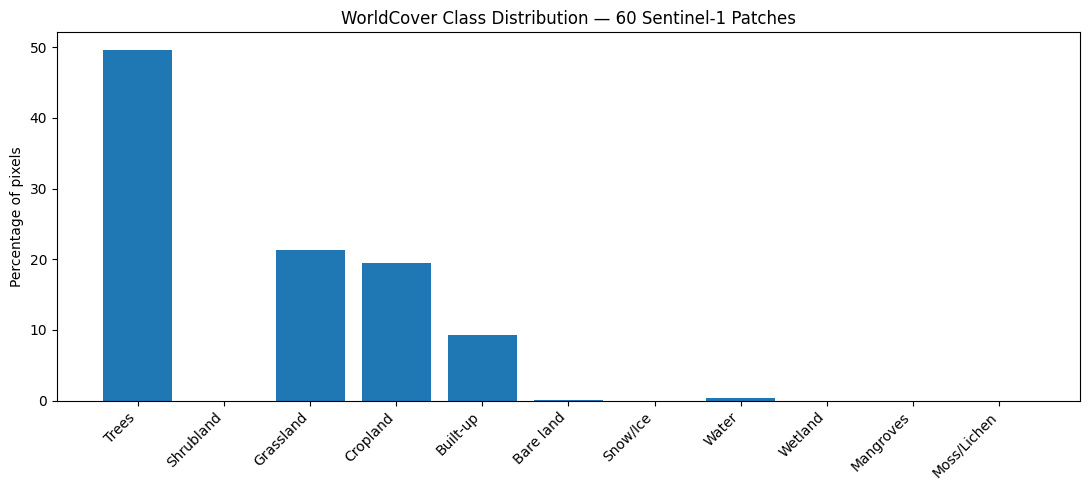

Total pixels: 3932160


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

counts = np.bincount(Y.flatten(), minlength=256)

total_pixels = Y.size

rows = []

for i, name in enumerate(CLASS_NAMES):
    count = int(counts[i])
    percentage = 100 * count / total_pixels

    rows.append({
        "Class": name,
        "Pixels": count,
        "Percentage": round(percentage, 4)
    })

class_df = pd.DataFrame(rows)

display(class_df)

plt.figure(figsize=(11, 5))
plt.bar(class_df["Class"], class_df["Percentage"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Percentage of pixels")
plt.title("WorldCover Class Distribution — 60 Sentinel-1 Patches")
plt.tight_layout()
plt.show()

print("Total pixels:", total_pixels)

In [5]:
import ee

ee.Authenticate()
ee.Initialize(project="mydataportfolio-484121")

print("Google Earth Engine connected successfully!")

Google Earth Engine connected successfully!


In [6]:
germany_states = ee.FeatureCollection(
    "FAO/GAUL/2015/level1"
)

baden_wurttemberg = germany_states.filter(
    ee.Filter.And(
        ee.Filter.eq("ADM0_NAME", "Germany"),
        ee.Filter.eq("ADM1_NAME", "Baden-Wuerttemberg")
    )
)

study_area = baden_wurttemberg.geometry()

print("Study area restored!")

Study area restored!


/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)


In [7]:
candidate_points = ee.FeatureCollection.randomPoints(
    region=study_area,
    points=120,
    seed=42,
    maxError=100
)

coordinates = [
    feature["geometry"]["coordinates"]
    for feature in candidate_points.getInfo()["features"]
]

print("Candidate locations:", len(coordinates))
print("First location:", coordinates[0])

Candidate locations: 120
First location: [8.96450860649046, 47.96931977124348]


In [8]:
import numpy as np
import glob
import re

files = sorted(glob.glob(
    "/content/drive/MyDrive/LULC_Project_Batch/patch_*.tif"
))

patch_ids = [
    int(re.search(r"patch_(\d+)\.tif$", f).group(1))
    for f in files
]

assert len(files) == 60, "Expected 60 patch files"
assert patch_ids == list(range(60)), "Patch order mismatch"
assert len(X) == 60, "Dataset must contain 60 patches"
assert len(coordinates) == 120, "Candidate coordinates missing"

# Confirm original random-point generation matches
assert np.allclose(
    coordinates[0],
    [8.964508607565648, 47.96931977168725],
    atol=1e-8
), "Coordinates differ from original sampling"

patch_coords = np.array(
    [coordinates[i] for i in patch_ids]
)

print("Matched patches:", len(patch_coords))
print("First coordinate:", patch_coords[0])

Matched patches: 60
First coordinate: [ 8.96450861 47.96931977]


In [9]:
from sklearn.model_selection import GroupShuffleSplit
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:3035",
    always_xy=True
)

east, north = transformer.transform(
    patch_coords[:, 0],
    patch_coords[:, 1]
)

# 20-km spatial blocks
grid_x = np.floor(np.array(east) / 20000).astype(int)
grid_y = np.floor(np.array(north) / 20000).astype(int)

groups = np.array([
    f"{gx}_{gy}"
    for gx, gy in zip(grid_x, grid_y)
])

indices = np.arange(len(X))

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, remaining_idx = next(
    splitter.split(indices, groups=groups)
)

second_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_local, test_local = next(
    second_splitter.split(
        remaining_idx,
        groups=groups[remaining_idx]
    )
)

val_idx = remaining_idx[val_local]
test_idx = remaining_idx[test_local]

print("Training patches:", len(train_idx))
print("Validation patches:", len(val_idx))
print("Testing patches:", len(test_idx))

assert set(groups[train_idx]).isdisjoint(groups[val_idx])
assert set(groups[train_idx]).isdisjoint(groups[test_idx])
assert set(groups[val_idx]).isdisjoint(groups[test_idx])

print("Geographic split verified!")

Training patches: 43
Validation patches: 8
Testing patches: 9
Geographic split verified!


In [10]:
CLASS_NAMES = [
    "Trees", "Shrubland", "Grassland",
    "Cropland", "Built-up", "Bare land",
    "Snow/Ice", "Water", "Wetland",
    "Mangroves", "Moss/Lichen"
]

def check_distribution(name, idx):
    counts = np.bincount(
        Y[idx].flatten(),
        minlength=256
    )

    print(f"\n{name}: {len(idx)} patches")

    for i, class_name in enumerate(CLASS_NAMES):
        if counts[i] > 0:
            percentage = 100 * counts[i] / Y[idx].size
            print(f"{class_name}: {percentage:.3f}%")

check_distribution("TRAIN", train_idx)
check_distribution("VALIDATION", val_idx)
check_distribution("TEST", test_idx)


TRAIN: 43 patches
Trees: 49.774%
Grassland: 20.190%
Cropland: 21.032%
Built-up: 8.660%
Bare land: 0.069%
Water: 0.276%
Wetland: 0.000%

VALIDATION: 8 patches
Trees: 52.646%
Grassland: 19.839%
Cropland: 14.429%
Built-up: 11.761%
Bare land: 0.048%
Water: 1.277%
Wetland: 0.000%

TEST: 9 patches
Trees: 46.262%
Grassland: 27.488%
Cropland: 16.077%
Built-up: 9.645%
Bare land: 0.198%
Water: 0.330%
Wetland: 0.000%


In [11]:
import os

output_dir = "/content/drive/MyDrive/LULC_Project"
os.makedirs(output_dir, exist_ok=True)

np.savez(
    os.path.join(output_dir, "geographic_split.npz"),
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    patch_coords=patch_coords,
    groups=groups
)

print("Geographic split saved successfully!")

Geographic split saved successfully!


In [1]:
from google.colab import drive
import ee
import os
import torch
import numpy as np

# Connect Google Drive
drive.mount("/content/drive")

# Connect Google Earth Engine
try:
    ee.Initialize(project="mydataportfolio-484121")
except Exception:
    ee.Authenticate()
    ee.Initialize(project="mydataportfolio-484121")

print("Google Earth Engine connected!")

# Verify existing project
folder = "/content/drive/MyDrive/LULC_Project"

files = [
    "training_dataset.npz",
    "unet_sentinel1.pth",
    "unet_sentinel1_backup.pth",
    "app.py",
    "requirements.txt"
]

for filename in files:
    print(
        filename,
        "FOUND" if os.path.exists(
            os.path.join(folder, filename)
        ) else "MISSING"
    )

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
Google Earth Engine connected!
training_dataset.npz FOUND
unet_sentinel1.pth FOUND
unet_sentinel1_backup.pth FOUND
app.py FOUND
requirements.txt FOUND

GPU available: True
GPU: Tesla T4


In [2]:
import ee
import numpy as np
import requests
from pyproj import Transformer
from rasterio.io import MemoryFile

# Mannheim city centre
lat, lon = 49.4875, 8.4660

transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:3035", always_xy=True
)

cx, cy = transformer.transform(lon, lat)

xmin = cx - 1280
ymax = cy + 1280

region = ee.Geometry.Rectangle(
    [cx - 1280, cy - 1280, cx + 1280, cy + 1280],
    proj="EPSG:3035",
    geodesic=False
)

# Sentinel-1 radar: 2021
s1 = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(region)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"))
    .select(["VV", "VH"])
)

print("Sentinel-1 scenes:", s1.size().getInfo())

# WorldCover 2021 labels
worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
    .rename("label")
    .toFloat()
)

combined = s1.median().toFloat().addBands(worldcover)

url = combined.getDownloadURL({
    "bands": ["VV", "VH", "label"],
    "crs": "EPSG:3035",
    "crs_transform": [10, 0, xmin, 0, -10, ymax],
    "dimensions": [256, 256],
    "format": "GEO_TIFF"
})

response = requests.get(url, timeout=120)
response.raise_for_status()

with MemoryFile(response.content) as mem:
    with mem.open() as src:
        patch = src.read(masked=True)
        print("Band names:", src.descriptions)

print("Patch shape:", patch.shape)
print("Invalid pixel count:", np.ma.getmaskarray(patch).sum())

# Check normalization and labels
vv = (np.clip(patch[0], -30, 5) + 30) / 35
vh = (np.clip(patch[1], -35, 0) + 35) / 35
labels = patch[2]

print("VV mean:", round(float(vv.mean()), 4))
print("VH mean:", round(float(vh.mean()), 4))
print("Trees:", round(float((labels == 10).mean() * 100), 2), "%")
print("Built-up:", round(float((labels == 50).mean() * 100), 2), "%")
print("Label codes:", np.unique(labels.compressed()))

Sentinel-1 scenes: 109
Band names: (None, None, None)
Patch shape: (3, 256, 256)
Invalid pixel count: 0
VV mean: 0.6905
VH mean: 0.636
Trees: 13.53 %
Built-up: 72.32 %
Label codes: [10. 30. 40. 50. 60. 80.]


In [3]:
import os
import time
import ee
import requests
import numpy as np
from pyproj import Transformer
from rasterio.io import MemoryFile

folder = "/content/drive/MyDrive/LULC_Project"
save_path = os.path.join(folder, "urban_training_additions.npz")

cities = {
    "Mannheim": (49.4875, 8.4660),
    "Heidelberg": (49.3988, 8.6724),
    "Karlsruhe": (49.0069, 8.4037),
    "Freiburg": (47.9990, 7.8421),
    "Heilbronn": (49.1427, 9.2109),
    "Ulm": (48.4011, 9.9876),
    "Tuebingen": (48.5216, 9.0576),
    "Pforzheim": (48.8906, 8.7029),
    "Offenburg": (48.4735, 7.9445)
}

# Five patches per city, spread 5 km apart
offsets = [
    (0, 0),
    (-5000, 0),
    (5000, 0),
    (0, -5000),
    (0, 5000)
]

worldcover_codes = [
    10, 20, 30, 40, 50, 60,
    70, 80, 90, 95, 100
]

transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:3035",
    always_xy=True
)

worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
    .rename("label")
    .toFloat()
)

# Load checkpoint if the collection was interrupted
X_new, Y_new, patch_ids, patch_cities = [], [], [], []

if os.path.exists(save_path):
    previous = np.load(save_path)
    X_new = list(previous["X"])
    Y_new = list(previous["Y"])
    patch_ids = list(previous["patch_ids"])
    patch_cities = list(previous["cities"])
    print("Resuming from", len(patch_ids), "saved patches")

for city, (lat, lon) in cities.items():

    cx, cy = transformer.transform(lon, lat)

    for j, (dx, dy) in enumerate(offsets):

        patch_id = f"{city}_{j}"

        if patch_id in patch_ids:
            continue

        x = cx + dx
        y = cy + dy

        xmin, ymax = x - 1280, y + 1280

        region = ee.Geometry.Rectangle(
            [x - 1280, y - 1280,
             x + 1280, y + 1280],
            proj="EPSG:3035",
            geodesic=False
        )

        try:
            s1 = (
                ee.ImageCollection("COPERNICUS/S1_GRD")
                .filterBounds(region)
                .filterDate("2021-01-01", "2022-01-01")
                .filter(ee.Filter.eq("instrumentMode", "IW"))
                .filter(ee.Filter.eq(
                    "orbitProperties_pass", "DESCENDING"
                ))
                .filter(ee.Filter.listContains(
                    "transmitterReceiverPolarisation", "VV"
                ))
                .filter(ee.Filter.listContains(
                    "transmitterReceiverPolarisation", "VH"
                ))
                .select(["VV", "VH"])
            )

            if s1.size().getInfo() == 0:
                print("Skipped (no scenes):", patch_id)
                continue

            combined = (
                s1.median()
                .toFloat()
                .addBands(worldcover)
            )

            url = combined.getDownloadURL({
                "bands": ["VV", "VH", "label"],
                "crs": "EPSG:3035",
                "crs_transform": [
                    10, 0, xmin, 0, -10, ymax
                ],
                "dimensions": [256, 256],
                "format": "GEO_TIFF"
            })

            response = requests.get(url, timeout=120)
            response.raise_for_status()

            with MemoryFile(response.content) as mem:
                with mem.open() as src:
                    patch = src.read(masked=True)

            if patch.shape != (3, 256, 256):
                raise ValueError("Invalid patch shape")

            if np.ma.getmaskarray(patch).any():
                raise ValueError("Masked pixels found")

            patch = patch.data.astype(np.float32)

            if not np.isfinite(patch).all():
                raise ValueError("Non-finite values found")

            vv = (
                np.clip(patch[0], -30, 5) + 30
            ) / 35

            vh = (
                np.clip(patch[1], -35, 0) + 35
            ) / 35

            raw_labels = np.rint(
                patch[2]
            ).astype(np.int16)

            labels = np.full(
                (256, 256), -1, dtype=np.int16
            )

            for class_idx, code in enumerate(worldcover_codes):
                labels[raw_labels == code] = class_idx

            if np.any(labels == -1):
                raise ValueError("Unknown WorldCover labels")

            X_new.append(
                np.stack([vv, vh]).astype(np.float32)
            )
            Y_new.append(labels.astype(np.uint8))
            patch_ids.append(patch_id)
            patch_cities.append(city)

            print(
                f"Saved {patch_id} | "
                f"Trees: {np.mean(labels == 0)*100:.1f}% | "
                f"Built-up: {np.mean(labels == 4)*100:.1f}%"
            )

        except Exception as error:
            print("Failed:", patch_id, str(error)[:200])

        # Save after each attempt so the work is recoverable
        if X_new:
            np.savez_compressed(
                save_path,
                X=np.stack(X_new),
                Y=np.stack(Y_new),
                patch_ids=np.array(patch_ids),
                cities=np.array(patch_cities)
            )

print("\n===== COLLECTION COMPLETE =====")
print("Total new patches:", len(X_new))

if X_new:
    print("X shape:", np.stack(X_new).shape)
    print("Y shape:", np.stack(Y_new).shape)
    print("Dataset saved:", save_path)

Saved Mannheim_0 | Trees: 13.5% | Built-up: 72.3%
Saved Mannheim_1 | Trees: 28.9% | Built-up: 31.3%
Saved Mannheim_2 | Trees: 32.4% | Built-up: 37.5%
Saved Mannheim_3 | Trees: 48.1% | Built-up: 9.6%
Saved Mannheim_4 | Trees: 17.6% | Built-up: 61.9%
Saved Heidelberg_0 | Trees: 17.5% | Built-up: 55.3%
Saved Heidelberg_1 | Trees: 6.9% | Built-up: 18.4%
Saved Heidelberg_2 | Trees: 99.2% | Built-up: 0.7%
Saved Heidelberg_3 | Trees: 15.0% | Built-up: 45.5%
Saved Heidelberg_4 | Trees: 39.8% | Built-up: 25.8%
Saved Karlsruhe_0 | Trees: 33.3% | Built-up: 62.1%
Saved Karlsruhe_1 | Trees: 33.8% | Built-up: 53.5%
Saved Karlsruhe_2 | Trees: 44.2% | Built-up: 30.8%
Saved Karlsruhe_3 | Trees: 33.4% | Built-up: 18.1%
Saved Karlsruhe_4 | Trees: 58.3% | Built-up: 24.0%
Saved Freiburg_0 | Trees: 32.4% | Built-up: 65.3%
Saved Freiburg_1 | Trees: 63.1% | Built-up: 11.6%
Saved Freiburg_2 | Trees: 96.7% | Built-up: 0.7%
Saved Freiburg_3 | Trees: 74.9% | Built-up: 5.0%
Saved Freiburg_4 | Trees: 80.1% | Built-